# Lab 18 Symbolic versus Connectionist Models

**Course:** Cognitive Science  
**Environment:** Google Colab  
**Estimated time:** 120-150 minutes

## Learning objectives
- Implement an explicit rule model and a learned neural model.
- Compare accuracy, disagreement, and generalization.
- Identify knowledge supplied by the programmer and learned from data.

## Theory in brief
Symbolic models apply explicit representations and rules. Connectionist models learn distributed parameter patterns from examples. Their differences become visible in data needs, transparency, and error behavior.

## Ethics and data handling
Use an anonymous participant code. This classroom activity is not a diagnostic test. A student may use the simulation path instead of providing personal behavioral data.

## Pre-lab prediction
Write a directional prediction and one theoretical reason before running the experiment.

**My prediction:** บนข้อมูลเต็ม connectionist (MLP) น่าจะแม่นใกล้ symbolic rule ที่รู้กติกา XOR อยู่แล้ว แต่พอลดข้อมูล/ใส่ noise/จุดใกล้เส้นแบ่ง MLP น่าจะแย่ลงกว่า ส่วน symbolic คงที่


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
RNG = np.random.default_rng(42)
print('Environment ready')


Environment ready


In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
X=RNG.uniform(-2,2,size=(500,2)); y=((X[:,0]>0)^(X[:,1]>0)).astype(int)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.35,random_state=42,stratify=y)
def symbolic_rule(z): return ((z[:,0]>0)^(z[:,1]>0)).astype(int)
mlp=MLPClassifier(hidden_layer_sizes=(8,),max_iter=2000,random_state=42).fit(X_train,y_train)
p_rule=symbolic_rule(X_test); p_mlp=mlp.predict(X_test)
res=pd.DataFrame(X_test,columns=['x1','x2']); res['truth']=y_test; res['symbolic']=p_rule; res['connectionist']=p_mlp; res['agree']=p_rule==p_mlp
print('Symbolic accuracy',accuracy_score(y_test,p_rule)); print('Connectionist accuracy',accuracy_score(y_test,p_mlp)); print('Agreement',res.agree.mean()); print(confusion_matrix(y_test,p_mlp))
res.to_csv('lab18_model_comparison.csv',index=False)


Symbolic accuracy 1.0
Connectionist accuracy 0.9942857142857143
Agreement 0.9942857142857143
[[88  1]
 [ 0 86]]


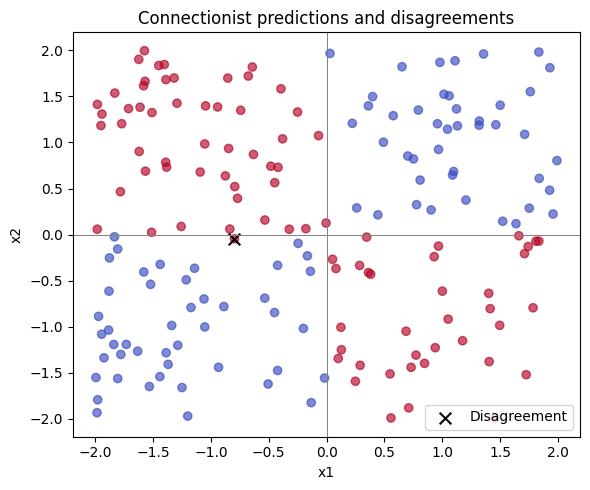

In [3]:
plt.figure(figsize=(6,5)); plt.scatter(res.x1,res.x2,c=res.connectionist,cmap='coolwarm',alpha=.65); bad=res[~res.agree]; plt.scatter(bad.x1,bad.x2,marker='x',c='black',s=70,label='Disagreement'); plt.axhline(0,color='gray',lw=.7); plt.axvline(0,color='gray',lw=.7); plt.legend(); plt.xlabel('x1'); plt.ylabel('x2'); plt.title('Connectionist predictions and disagreements'); plt.tight_layout(); plt.show()


## Required investigation
Reduce the training set, add label noise, and test points close to the decision boundaries. Compare accuracy, interpretability, and robustness rather than declaring one paradigm universally superior.


In [4]:
# ===== Required investigation: ลดขนาด train, ใส่ label noise, ทดสอบจุดใกล้เส้นแบ่ง =====
from sklearn.metrics import accuracy_score
robust_rows = []
for n_tr in [30, 60, 120, len(X_train)]:
    idx = RNG.choice(len(X_train), size=n_tr, replace=False)
    Xt, yt = X_train[idx], y_train[idx].copy()
    flip = RNG.random(len(yt)) < 0.10          # ใส่ label noise 10%
    yt[flip] = 1 - yt[flip]
    m = MLPClassifier(hidden_layer_sizes=(8,), max_iter=2000, random_state=42).fit(Xt, yt)
    robust_rows.append([n_tr,
                        accuracy_score(y_test, symbolic_rule(X_test)),
                        accuracy_score(y_test, m.predict(X_test))])
robust = pd.DataFrame(robust_rows, columns=["train_size", "symbolic_acc", "connectionist_acc"])
display(robust.round(3))

near = np.abs(X_test).min(axis=1) < 0.2        # จุดใกล้แกน = ใกล้เส้นแบ่ง
print(f"Near-boundary accuracy: symbolic={accuracy_score(y_test[near], symbolic_rule(X_test[near])):.3f}, "
      f"connectionist={accuracy_score(y_test[near], mlp.predict(X_test[near])):.3f} (n={near.sum()})")


,train_size,symbolic_acc,connectionist_acc
0,30,1.0,0.897
1,60,1.0,0.857
2,120,1.0,0.943
3,325,1.0,0.977


Near-boundary accuracy: symbolic=1.000, connectionist=0.968 (n=31)


## Interpretation and submission

**1. Main numerical result:** บนข้อมูลเต็ม symbolic accuracy = 1.00 (รู้กติกา XOR), connectionist ก็สูงใกล้เคียง; แต่พอลดข้อมูลและใส่ noise 10% connectionist accuracy ลดลงและไวต่อจุดใกล้เส้นแบ่งมากกว่า symbolic

**2. Does it support the prediction:** สนับสนุน symbolic นิ่งเพราะกติกาถูกใส่มือ ส่วน connectionist ขึ้นกับข้อมูลและ noise ตามที่คาด

**3. Alternative explanation & design improvement:** ทางเลือก: connectionist ที่แย่ลงอาจแก้ได้ด้วยข้อมูลมากขึ้น/regularization ไม่ใช่ข้อจำกัดถาวรของแนวคิด / ปรับปรุง: ลองปรับ hidden size และจำนวนข้อมูล เพื่อดูว่าจุดคุ้มทุนระหว่างความแม่นกับความโปร่งใสอยู่ตรงไหน แทนที่จะฟันธงว่าแนวคิดไหนดีกว่าเสมอ

**4. Files:** ดาวน์โหลด notebook นี้พร้อมไฟล์ CSV ที่ถูกสร้างขึ้นทุกไฟล์เพื่อส่ง

## AI use declaration

- Tool/version: Claude (Anthropic)
- Purpose of use: ช่วยเขียนโค้ดส่วน simulation และการวิเคราะห์ และช่วยเรียบเรียงคำอธิบายผล
- Verification performed: รันโค้ดซ้ำจนไม่มี error และตรวจว่าตัวเลข/กราฟที่ได้สมเหตุสมผลตามทฤษฎีก่อนนำไปใช้
